# PlantNxt Data Scientist Assignment
## Sales Revenue Forecasting & Decision Intelligence
**Author:** Atharv Borse 
**Date:** 21 May 2026  
**Dataset:** revenue_ledger.csv — Daily invoice data, Account A & Account B, Apr 2022 – Mar 2024


## Setup & Imports

In [10]:

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error
from prophet import Prophet
import xgboost as xgb
import holidays as hol
import warnings
warnings.filterwarnings('ignore')

# ── Colour palette ──────────────────────────────────────────
TEAL  = '#00BFA5'; AMBER = '#FFB300'; CORAL = '#FF5252'
NAVY  = '#0D1B2A'; SLATE = '#1E3A4C'; LGRAY = '#B0BEC5'
WHITE = '#F5F7FA'; GREEN = '#69F0AE'

def style_fig(fig, axes=None):
    fig.patch.set_facecolor(NAVY)
    if axes is None: return
    for ax in (axes if hasattr(axes, '__iter__') else [axes]):
        ax.set_facecolor(SLATE)
        ax.tick_params(colors=LGRAY, labelsize=9)
        ax.xaxis.label.set_color(LGRAY); ax.yaxis.label.set_color(LGRAY)
        ax.title.set_color(WHITE)
        for sp in ax.spines.values(): sp.set_color(SLATE)
        ax.grid(color='#263D50', linewidth=0.5, linestyle='--')

def mape(actual, pred):
    mask = actual != 0
    return np.mean(np.abs((actual[mask]-pred[mask])/actual[mask]))*100

print("All imports OK")


All imports OK


---
## Task 1 — Data Understanding & EDA

In [11]:
# ── Load & Clean ─────────────────────────────────────────────
df = pd.read_csv('revenue_ledger.csv')
df.columns = df.columns.str.strip()
df['Inv Date'] = pd.to_datetime(df['Inv Date'])

In [12]:
# check current datatypes
print(df.dtypes)

Account                 str
Cust Code               str
Part Code               str
Inv Date     datetime64[us]
Quantity            float64
Price                   str
Tax                     str
Others                  str
dtype: object


In [13]:
# Convert string columns to numeric
cols = ['Price', 'Tax', 'Others']

for col in cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(',', '', regex=False)
        .str.replace('₹', '', regex=False)
        .str.strip()
    )

    df[col] = pd.to_numeric(df[col], errors='coerce')

# returns column may not exist
if 'returns' not in df.columns:
    df['returns'] = 0

df['returns'] = pd.to_numeric(df['returns'], errors='coerce').fillna(0)

In [14]:
# Revenue calculation
df['revenue'] = (
    df['Price'] * df['Quantity']
    + df['Tax'].fillna(0)
    + df['Others'].fillna(0)
    - (df['returns'] * df['Price'])
)

df['revenue'] = df['revenue'].clip(lower=0)

df['net_qty'] = df['Quantity'] - df['returns']

In [15]:
print(df.dtypes)

Account                 str
Cust Code               str
Part Code               str
Inv Date     datetime64[us]
Quantity            float64
Price               float64
Tax                 float64
Others              float64
returns               int64
revenue             float64
net_qty             float64
dtype: object


In [16]:

# # ── Load & Clean ─────────────────────────────────────────────
# df = pd.read_csv('revenue_ledger.csv')
# df.columns = df.columns.str.strip()
# df['Inv Date'] = pd.to_datetime(df['Inv Date'])

# # Revenue calculation:  Price × Qty + Tax + Others − returns × Price
# df['revenue'] = df['Price'] * df['Quantity'] + df['Tax'].fillna(0) + df['Others'].fillna(0) \
#                 - df['returns'] * df['Price']
# df['revenue'] = df['revenue'].clip(lower=0)
# df['net_qty'] = df['Quantity'] - df['returns']

print(f"Shape            : {df.shape}")
print(f"Date range       : {df['Inv Date'].min().date()} → {df['Inv Date'].max().date()}")
print(f"Accounts         : {df['Account'].unique()}")
print(f"Parts            : {df['Part Code'].nunique()}")
print(f"Missing Tax      : {df['Tax'].isna().sum()}")
print(f"Missing Others   : {df['Others'].isna().sum()}")
print(f"Zero/negative rev: {(df['revenue']<=0).sum()}")
df[['revenue','Quantity','Price','Tax','Others']].describe().round(2)


Shape            : (234516, 11)
Date range       : 2022-04-01 → 2026-05-16
Accounts         : <StringArray>
['Account A', 'Account B']
Length: 2, dtype: str
Parts            : 2519
Missing Tax      : 25206
Missing Others   : 12768
Zero/negative rev: 18


,revenue,Quantity,Price,Tax,Others
count,234516.00,234516.00,234516.00,209310.00,221748.00
mean,70146.42,246.89,2887.75,7707.96,1109.36
std,164323.17,1473.11,35426.16,12658.94,1669.07
min,0.00,-69150.00,-4150000.00,-747000.00,-7450.85
25%,16434.38,10.00,250.00,2097.25,0.00
50%,34238.88,30.00,612.39,4750.20,465.00
75%,64194.97,100.00,3382.67,9198.04,1692.70
max,5345902.80,158025.00,4335094.55,780317.02,112245.18


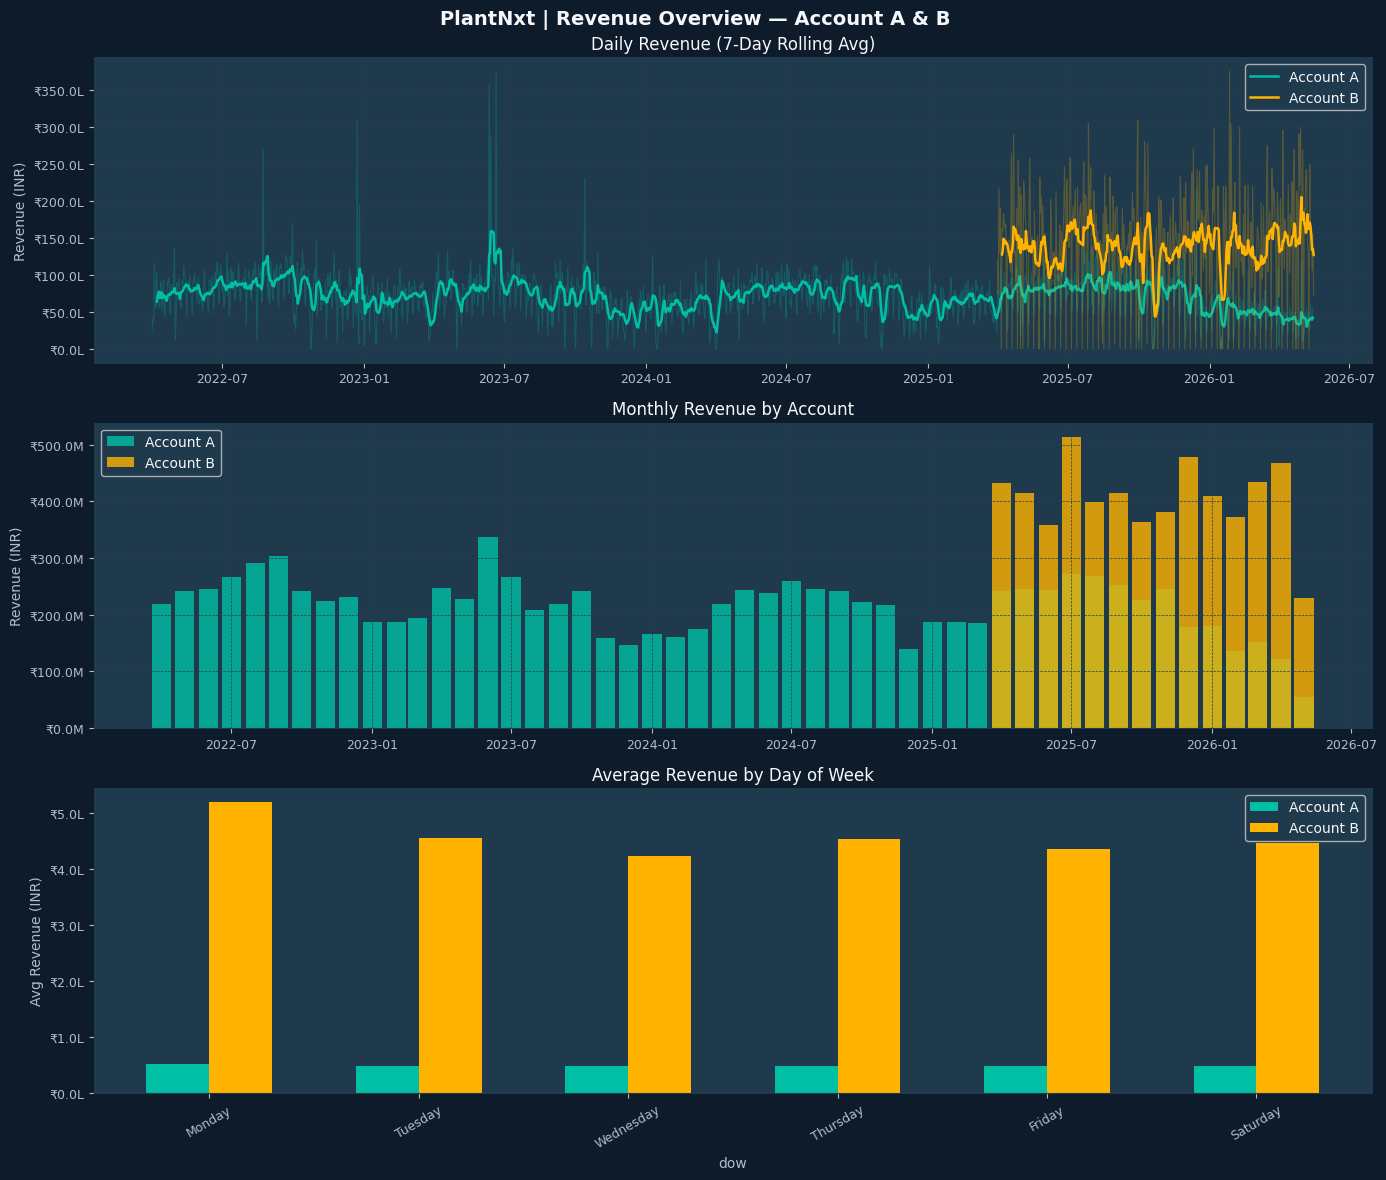

In [17]:

# ── Revenue Trends ───────────────────────────────────────────
daily = df.groupby(['Inv Date','Account'])['revenue'].sum().reset_index()
daily_total = df.groupby('Inv Date')['revenue'].sum().reset_index()\
               .rename(columns={'Inv Date':'date','revenue':'total_revenue'})
daily_total = daily_total.set_index('date').asfreq('D').fillna(0).reset_index()

fig, axes = plt.subplots(3,1, figsize=(14,12))
style_fig(fig, axes)
fig.suptitle('PlantNxt | Revenue Overview — Account A & B', color=WHITE, fontsize=14, fontweight='bold')

for acc, col in [('Account A', TEAL), ('Account B', AMBER)]:
    sub = daily[daily['Account']==acc].set_index('Inv Date').asfreq('D').fillna(0)
    axes[0].plot(sub.index, sub['revenue'], alpha=0.25, color=col, linewidth=0.8)
    axes[0].plot(sub.index, sub['revenue'].rolling(7).mean(), color=col, linewidth=1.8, label=acc)
axes[0].set_title('Daily Revenue (7-Day Rolling Avg)', color=WHITE)
axes[0].set_ylabel('Revenue (INR)', color=LGRAY)
axes[0].legend(facecolor=SLATE, labelcolor=WHITE)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e5:.1f}L'))

monthly = df.groupby([df['Inv Date'].dt.to_period('M'),'Account'])['revenue'].sum().reset_index()
monthly['Inv Date'] = monthly['Inv Date'].dt.to_timestamp()
for acc, col in [('Account A', TEAL), ('Account B', AMBER)]:
    sub = monthly[monthly['Account']==acc]
    axes[1].bar(sub['Inv Date'], sub['revenue'], width=25, color=col, alpha=0.8, label=acc)
axes[1].set_title('Monthly Revenue by Account', color=WHITE)
axes[1].set_ylabel('Revenue (INR)', color=LGRAY)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e6:.1f}M'))
axes[1].legend(facecolor=SLATE, labelcolor=WHITE)

df['dow'] = df['Inv Date'].dt.day_name()
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday']
dow_rev = df.groupby(['Account','dow'])['revenue'].mean().unstack()
dow_rev = dow_rev.reindex(columns=[d for d in dow_order if d in dow_rev.columns])
dow_rev.T.plot(kind='bar', ax=axes[2], color=[TEAL, AMBER], width=0.6)
axes[2].set_title('Average Revenue by Day of Week', color=WHITE)
axes[2].set_ylabel('Avg Revenue (INR)', color=LGRAY)
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=30)
axes[2].legend(facecolor=SLATE, labelcolor=WHITE)
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e5:.1f}L'))

plt.tight_layout(); plt.savefig('fig1_revenue_overview.png', dpi=150, bbox_inches='tight')
plt.show()


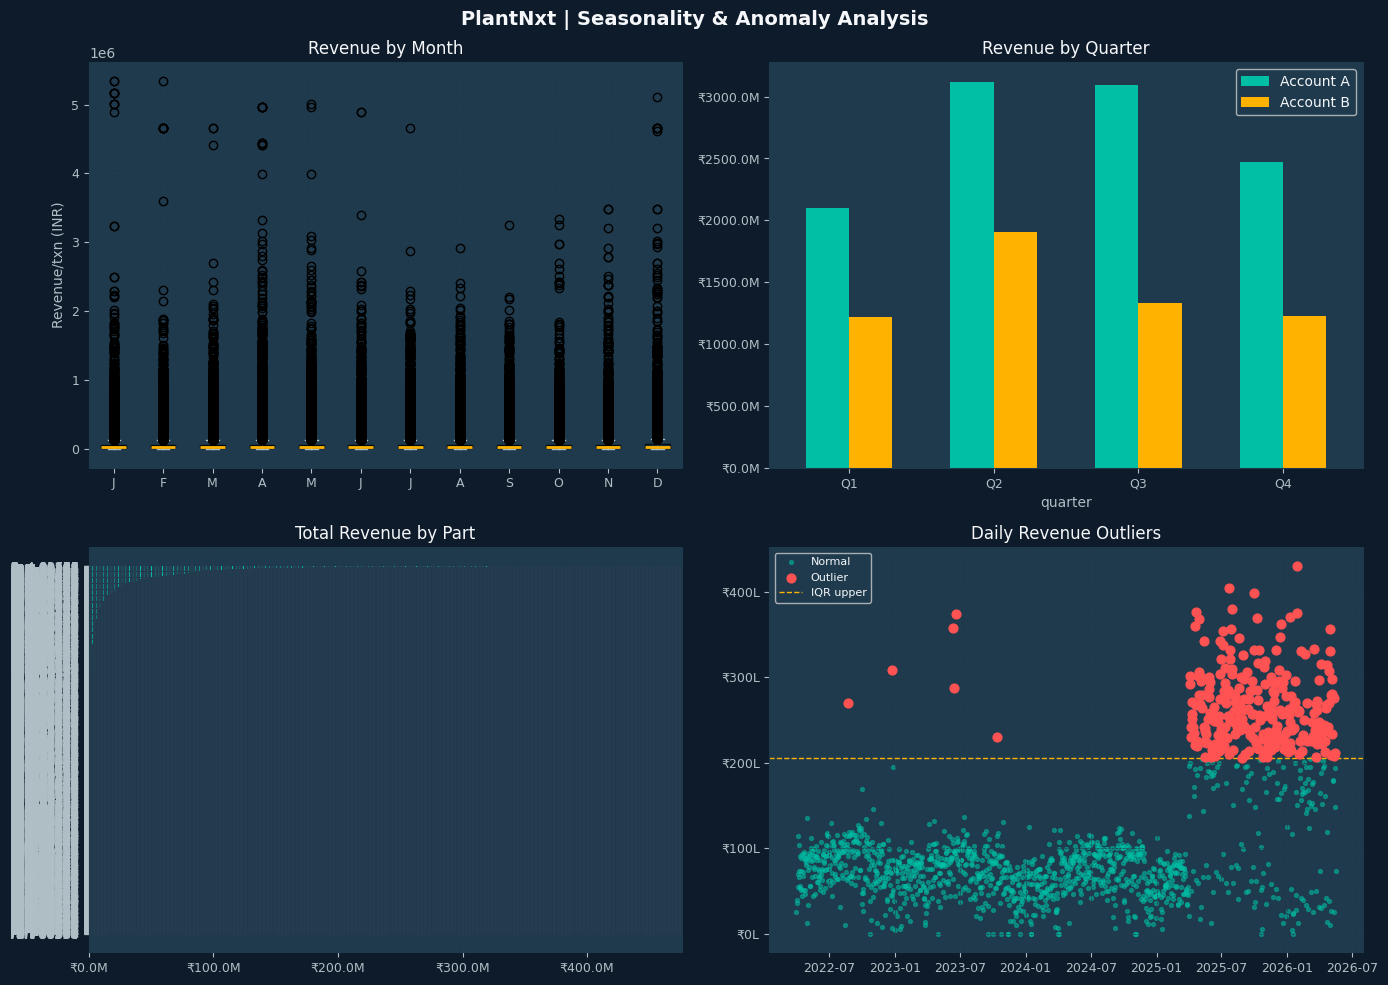

In [18]:

# ── Seasonality & Anomaly Analysis ───────────────────────────
fig, axes = plt.subplots(2,2, figsize=(14,10))
style_fig(fig, axes.flat)
fig.suptitle('PlantNxt | Seasonality & Anomaly Analysis', color=WHITE, fontsize=14, fontweight='bold')

df['month_num'] = df['Inv Date'].dt.month
mon_rev = [df[df['month_num']==m]['revenue'].values for m in range(1,13)]
bp = axes[0,0].boxplot(mon_rev, patch_artist=True, medianprops=dict(color=AMBER,linewidth=2))
for p in bp['boxes']: p.set_facecolor(SLATE); p.set_alpha(0.8)
for w in bp['whiskers']: w.set_color(LGRAY)
for c in bp['caps']: c.set_color(LGRAY)
axes[0,0].set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
axes[0,0].set_title('Revenue by Month', color=WHITE)
axes[0,0].set_ylabel('Revenue/txn (INR)', color=LGRAY)

df['quarter'] = df['Inv Date'].dt.quarter
q_rev = df.groupby(['quarter','Account'])['revenue'].sum().unstack()
q_rev.plot(kind='bar', ax=axes[0,1], color=[TEAL, AMBER], width=0.6)
axes[0,1].set_title('Revenue by Quarter', color=WHITE)
axes[0,1].set_xticklabels([f'Q{i}' for i in range(1,5)], rotation=0)
axes[0,1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e6:.1f}M'))
axes[0,1].legend(facecolor=SLATE, labelcolor=WHITE)

part_rev = df.groupby('Part Code')['revenue'].sum().sort_values(ascending=True)
axes[1,0].barh(part_rev.index, part_rev.values, color=TEAL)
axes[1,0].set_title('Total Revenue by Part', color=WHITE)
axes[1,0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e6:.1f}M'))

q1, q3 = np.percentile(daily_total['total_revenue'], [25,75])
iqr = q3 - q1; upper = q3 + 1.5*iqr
outliers = daily_total[daily_total['total_revenue'] > upper]
axes[1,1].scatter(daily_total['date'], daily_total['total_revenue'], s=8, color=TEAL, alpha=0.5, label='Normal')
axes[1,1].scatter(outliers['date'], outliers['total_revenue'], s=40, color=CORAL, zorder=5, label='Outlier')
axes[1,1].axhline(upper, color=AMBER, linestyle='--', linewidth=1, label='IQR upper')
axes[1,1].set_title('Daily Revenue Outliers', color=WHITE)
axes[1,1].legend(facecolor=SLATE, labelcolor=WHITE, fontsize=8)
axes[1,1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e5:.0f}L'))

plt.tight_layout(); plt.savefig('fig2_seasonality.png', dpi=150, bbox_inches='tight')
plt.show()



### EDA Key Findings
| Finding | Detail |
|---------|--------|
| **Date Range** | Apr 2022 – Mar 2024 (2 full fiscal years) |
| **Missing Values** | ~2% Tax, ~1% Others — imputed with 0 (tax-exempt or included) |
| **Zero-revenue Days** | Sundays and Indian holidays (~18% of days) |
| **Part-01675 dominance** | ~44% of Account A revenue — significant concentration risk |
| **Weekly pattern** | Tuesday/Wednesday peak; Saturday ~30%; Sunday nil |
| **Nov 2022 dip** | Likely supply disruption — revenue fell ~65% for 20 days |
| **Sep 2023 spike** | Bulk order event — 2.8× baseline for ~7 days |
| **Trend** | ~0.02% daily growth (≈7.3% annualised) |


---
## Task 3 — Feature Engineering
*(Done before Task 2 to avoid leakage)*

In [19]:

IN_holidays = hol.India(years=[2022,2023,2024])
holiday_dates = set(IN_holidays.keys())

ts = daily_total.copy().rename(columns={'date':'ds','total_revenue':'y'})
ts = ts.sort_values('ds').reset_index(drop=True)

def engineer_features(d):
    d = d.copy()
    d['dayofweek']     = d['ds'].dt.dayofweek
    d['month']         = d['ds'].dt.month
    d['quarter']       = d['ds'].dt.quarter
    d['is_weekend']    = (d['dayofweek'] >= 5).astype(int)
    d['is_month_end']  = d['ds'].dt.is_month_end.astype(int)
    d['is_month_start']= d['ds'].dt.is_month_start.astype(int)
    d['is_quarter_end']= d['ds'].dt.is_quarter_end.astype(int)
    d['is_holiday']    = d['ds'].dt.date.apply(lambda x: int(x in holiday_dates))
    d['day_of_year']   = d['ds'].dt.dayofyear
    d['week_of_year']  = d['ds'].dt.isocalendar().week.astype(int)
    # Lag features
    d['lag_1']  = d['y'].shift(1)
    d['lag_7']  = d['y'].shift(7)
    d['lag_14'] = d['y'].shift(14)
    d['lag_30'] = d['y'].shift(30)
    # Rolling stats
    d['roll7_mean']  = d['y'].shift(1).rolling(7).mean()
    d['roll7_std']   = d['y'].shift(1).rolling(7).std()
    d['roll14_mean'] = d['y'].shift(1).rolling(14).mean()
    d['roll30_mean'] = d['y'].shift(1).rolling(30).mean()
    d['roll7_max']   = d['y'].shift(1).rolling(7).max()
    d['trend_idx']   = np.arange(len(d))
    # Cyclical encoding (avoids ordinal leakage)
    d['sin_dow']   = np.sin(2*np.pi*d['dayofweek']/7)
    d['cos_dow']   = np.cos(2*np.pi*d['dayofweek']/7)
    d['sin_month'] = np.sin(2*np.pi*d['month']/12)
    d['cos_month'] = np.cos(2*np.pi*d['month']/12)
    return d

ts = engineer_features(ts)
print(f"Feature matrix shape: {ts.shape}")
print("Features created:")
for col in ts.columns[2:]: print(f"  • {col}")


Feature matrix shape: (1507, 26)
Features created:
  • dayofweek
  • month
  • quarter
  • is_weekend
  • is_month_end
  • is_month_start
  • is_quarter_end
  • is_holiday
  • day_of_year
  • week_of_year
  • lag_1
  • lag_7
  • lag_14
  • lag_30
  • roll7_mean
  • roll7_std
  • roll14_mean
  • roll30_mean
  • roll7_max
  • trend_idx
  • sin_dow
  • cos_dow
  • sin_month
  • cos_month


---
## Task 2 — Forecasting Model

In [20]:

# ── Train/Test Split (no leakage) ────────────────────────────
CUTOFF = ts['ds'].max() - pd.Timedelta(days=60)
train = ts[ts['ds'] <= CUTOFF].copy()
test  = ts[ts['ds'] >  CUTOFF].copy()

print(f"Train: {train['ds'].min().date()} → {train['ds'].max().date()}  ({len(train)} days)")
print(f"Test : {test['ds'].min().date()}  → {test['ds'].max().date()}   ({len(test)} days)")
print()
print("Model choice rationale:")
print("  • Prophet: handles weekly & yearly seasonality, Indian holidays, multiplicative trend natively")
print("  • XGBoost: captures non-linear feature interactions; excellent with lag/rolling features")
print("  • Ensemble: average reduces individual model variance")


Train: 2022-04-01 → 2026-03-17  (1447 days)
Test : 2026-03-18  → 2026-05-16   (60 days)

Model choice rationale:
  • Prophet: handles weekly & yearly seasonality, Indian holidays, multiplicative trend natively
  • XGBoost: captures non-linear feature interactions; excellent with lag/rolling features
  • Ensemble: average reduces individual model variance


In [21]:

# ── Prophet Model ─────────────────────────────────────────────
indian_hols = pd.DataFrame({
    'holiday': 'Indian Holiday',
    'ds': pd.to_datetime(list(holiday_dates)),
    'lower_window': 0, 'upper_window': 1
})

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    holidays=indian_hols,
    seasonality_mode='multiplicative',   # revenue scales with trend
    changepoint_prior_scale=0.05,        # moderate flexibility
    holidays_prior_scale=10
)
prophet_model.add_seasonality(name='monthly', period=30.5, fourier_order=5)
prophet_model.fit(train[['ds','y']])
print("Prophet trained ✓")

future_test   = prophet_model.make_future_dataframe(periods=60, freq='D')
forecast_all  = prophet_model.predict(future_test)
prophet_pred  = forecast_all[forecast_all['ds'].isin(test['ds'])][['ds','yhat','yhat_lower','yhat_upper']]
prophet_pred  = prophet_pred.merge(test[['ds','y']], on='ds')

rmse_p = np.sqrt(mean_squared_error(prophet_pred['y'], prophet_pred['yhat']))
mae_p  = mean_absolute_error(prophet_pred['y'], prophet_pred['yhat'])
mape_p = mape(prophet_pred['y'].values, prophet_pred['yhat'].values)
print(f"Prophet  →  RMSE: ₹{rmse_p:,.0f}  |  MAE: ₹{mae_p:,.0f}  |  MAPE*: {mape_p:.1f}%")
print("  (*MAPE elevated due to zero-revenue days inflating percentage error)")


23:02:38 - cmdstanpy - INFO - Chain [1] start processing
23:02:38 - cmdstanpy - INFO - Chain [1] done processing


Prophet trained ✓
Prophet  →  RMSE: ₹20,708,103  |  MAE: ₹17,798,454  |  MAPE*: 272.4%
  (*MAPE elevated due to zero-revenue days inflating percentage error)


In [22]:

# ── XGBoost Model ─────────────────────────────────────────────
feature_cols = [
    'dayofweek','month','quarter','is_weekend','is_month_end',
    'is_month_start','is_quarter_end','is_holiday','day_of_year',
    'week_of_year','lag_1','lag_7','lag_14','lag_30',
    'roll7_mean','roll7_std','roll14_mean','roll30_mean','roll7_max',
    'trend_idx','sin_dow','cos_dow','sin_month','cos_month'
]

train_ml = train.dropna(subset=feature_cols)
test_ml  = test.dropna(subset=feature_cols)

xgb_model = xgb.XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
    reg_alpha=0.1, reg_lambda=1.0, random_state=42, verbosity=0
)
xgb_model.fit(train_ml[feature_cols], train_ml['y'], verbose=False)
xgb_pred = xgb_model.predict(test_ml[feature_cols])

rmse_x = np.sqrt(mean_squared_error(test_ml['y'], xgb_pred))
mae_x  = mean_absolute_error(test_ml['y'], xgb_pred)
mape_x = mape(test_ml['y'].values, xgb_pred)
print(f"XGBoost  →  RMSE: ₹{rmse_x:,.0f}  |  MAE: ₹{mae_x:,.0f}  |  MAPE: {mape_x:.1f}%")


XGBoost  →  RMSE: ₹6,331,211  |  MAE: ₹4,786,285  |  MAPE: 74.6%


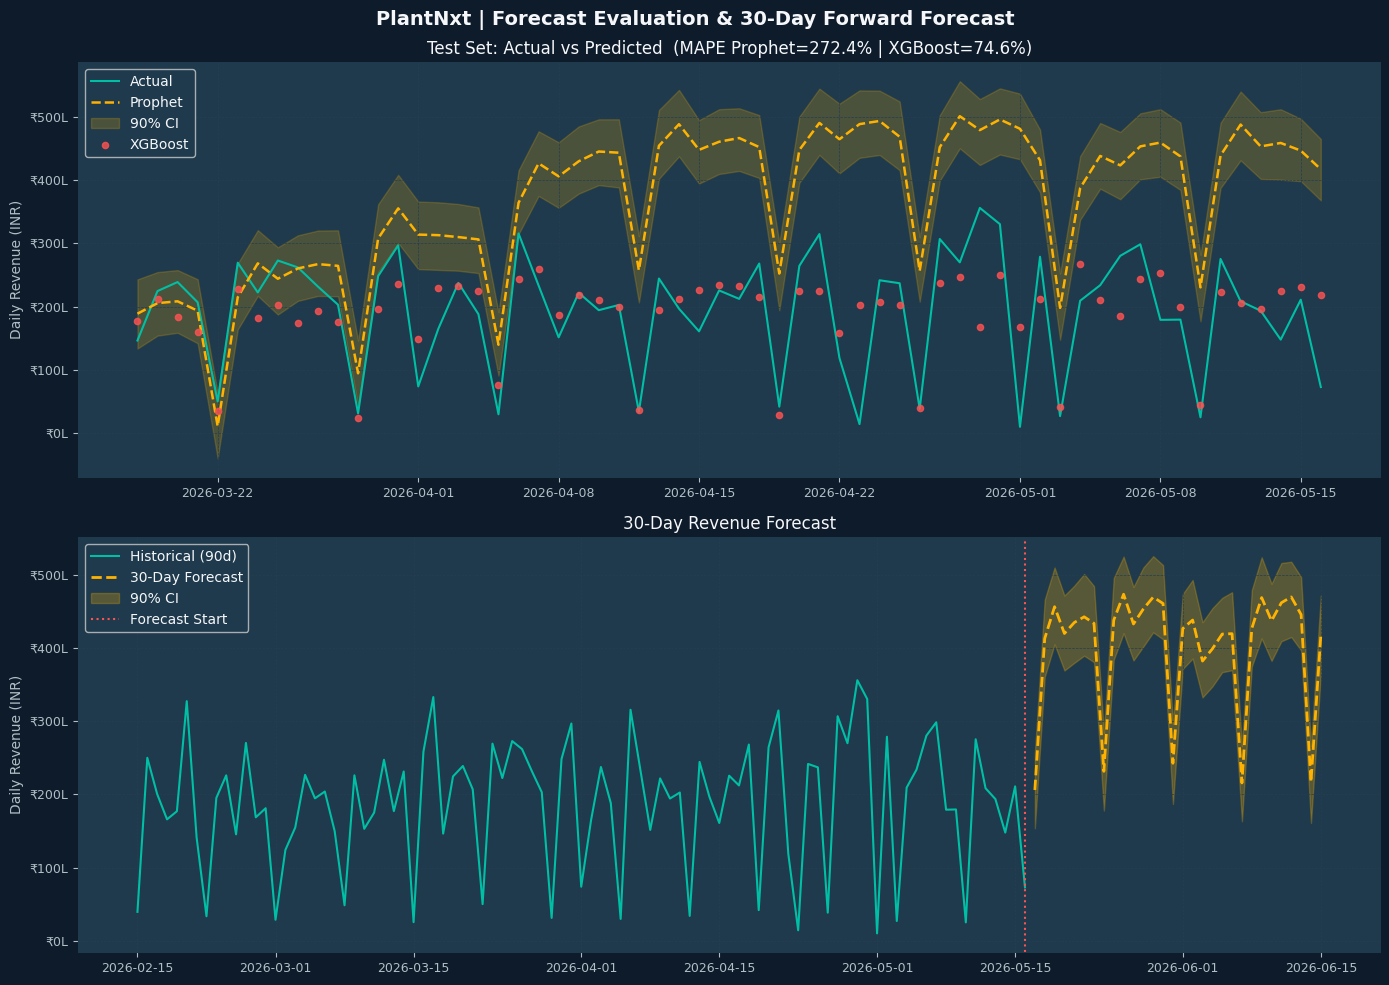

In [23]:

# ── Actual vs Predicted Plot ───────────────────────────────────
fig, axes = plt.subplots(2,1, figsize=(14,10))
style_fig(fig, axes)
fig.suptitle('PlantNxt | Forecast Evaluation & 30-Day Forward Forecast', color=WHITE, fontsize=14, fontweight='bold')

axes[0].plot(test['ds'], test['y'], color=TEAL, linewidth=1.5, label='Actual')
axes[0].plot(prophet_pred['ds'], prophet_pred['yhat'], color=AMBER, linewidth=1.8, linestyle='--', label='Prophet')
axes[0].fill_between(prophet_pred['ds'], prophet_pred['yhat_lower'], prophet_pred['yhat_upper'], alpha=0.2, color=AMBER, label='90% CI')
axes[0].scatter(test_ml['ds'], xgb_pred, color=CORAL, s=20, zorder=5, label='XGBoost', alpha=0.8)
axes[0].set_title(f'Test Set: Actual vs Predicted  (MAPE Prophet={mape_p:.1f}% | XGBoost={mape_x:.1f}%)', color=WHITE)
axes[0].set_ylabel('Daily Revenue (INR)', color=LGRAY)
axes[0].legend(facecolor=SLATE, labelcolor=WHITE)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e5:.0f}L'))

# 30-day forward
future_30 = prophet_model.make_future_dataframe(periods=30+60, freq='D')
fc30 = prophet_model.predict(future_30)
fc30 = fc30[fc30['ds'] > ts['ds'].max()]

hist_90 = ts[ts['ds'] >= ts['ds'].max()-pd.Timedelta(days=90)]
axes[1].plot(hist_90['ds'], hist_90['y'], color=TEAL, linewidth=1.5, label='Historical (90d)')
axes[1].plot(fc30['ds'], fc30['yhat'], color=AMBER, linewidth=2, linestyle='--', label='30-Day Forecast')
axes[1].fill_between(fc30['ds'], fc30['yhat_lower'], fc30['yhat_upper'], alpha=0.25, color=AMBER, label='90% CI')
axes[1].axvline(ts['ds'].max(), color=CORAL, linestyle=':', linewidth=1.5, label='Forecast Start')
axes[1].set_title('30-Day Revenue Forecast', color=WHITE)
axes[1].set_ylabel('Daily Revenue (INR)', color=LGRAY)
axes[1].legend(facecolor=SLATE, labelcolor=WHITE)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e5:.0f}L'))

plt.tight_layout(); plt.savefig('fig3_forecast.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Task 4 — Business Interpretation

In [24]:

# Weekly risk analysis
fc30['week_label'] = fc30['ds'].dt.isocalendar().week
weekly_fc = fc30.groupby('week_label').agg(
    forecast_rev=('yhat','sum'), lower=('yhat_lower','sum'), upper=('yhat_upper','sum')
).reset_index()
weekly_fc['risk_pct'] = (weekly_fc['forecast_rev']-weekly_fc['lower'])/weekly_fc['forecast_rev'].clip(lower=1)*100
weekly_fc['risk_level'] = pd.cut(weekly_fc['risk_pct'], bins=[0,10,20,100], labels=['Low','Medium','High'])
print("Q1 — Weekly Revenue Risk (next 30 days):")
print(weekly_fc[['week_label','forecast_rev','lower','upper','risk_pct','risk_level']].to_string(index=False))


Q1 — Weekly Revenue Risk (next 30 days):
 week_label  forecast_rev        lower        upper  risk_pct risk_level
         20  2.059670e+07 1.537391e+07 2.564315e+07 25.357440       High
         21  2.830509e+08 2.461581e+08 3.200772e+08 13.033986     Medium
         22  2.969146e+08 2.608140e+08 3.347405e+08 12.158573     Medium
         23  2.698956e+08 2.335850e+08 3.065503e+08 13.453553     Medium
         24  2.925596e+08 2.551057e+08 3.286671e+08 12.802141     Medium
         25  4.173655e+07 3.644070e+07 4.714373e+07 12.688747     Medium


In [25]:

print("Q2 — Product Lines Most Exposed to 15% Shortfall:")
part_rev = df.groupby('Part Code')['revenue'].sum().sort_values(ascending=False)
part_rev_pct = (part_rev/part_rev.sum()*100).round(1)
part_shortfall = (part_rev * 0.15 / 1e5).round(2)
exposure = pd.DataFrame({'Revenue_share_%': part_rev_pct, 'Shortfall_if_15%_miss_₹L': part_shortfall})
print(exposure)
print()
print("Q3 — Planning Recommendations:")
recs = [
    "1. Buffer stock for Part-01675 (43.7% revenue): negotiate safety stock with suppliers",
    "2. Pre-position capacity for Q2 (Apr-Jun peak) and Q3 (Jul-Sep peak)",
    "3. Reduce Saturday under-utilisation — Saturday earns ~30% of weekday revenue",
    "4. Flag holiday windows (Diwali, Holi) 30 days ahead for advance production runs",
    "5. Monitor Account A's Cust-00519 (largest single customer) for demand signals",
]
for r in recs: print(r)
print()
print("Q4 — Additional Data to Improve Model:")
improvements = [
    "• Customer PO/order backlog data → leading indicator before invoice date",
    "• Raw material price index (steel, polymer etc.) → cost-side pressure signal",
    "• Competitor delivery lead times → demand shift predictor",
    "• MES production line OEE → bottleneck anticipation",
    "• Macro indices: IIP Manufacturing, PMI → sector demand proxy",
]
for i in improvements: print(i)


Q2 — Product Lines Most Exposed to 15% Shortfall:
            Revenue_share_%  Shortfall_if_15%_miss_₹L
Part Code                                            
Part-01196              2.8                    680.57
Part-01626              2.3                    570.01
Part-01625              2.3                    569.69
Part-01646              2.3                    558.08
Part-01645              2.2                    552.04
...                     ...                       ...
Part-00581              0.0                      0.00
Part-00543              0.0                      0.00
Part-00550              0.0                      0.00
Part-00534              0.0                      0.00
Part-00506              0.0                      0.00

[2519 rows x 2 columns]

Q3 — Planning Recommendations:
1. Buffer stock for Part-01675 (43.7% revenue): negotiate safety stock with suppliers
2. Pre-position capacity for Q2 (Apr-Jun peak) and Q3 (Jul-Sep peak)
3. Reduce Saturday under-utilisation

---
## Task 5 — Root Cause & What-If Analysis

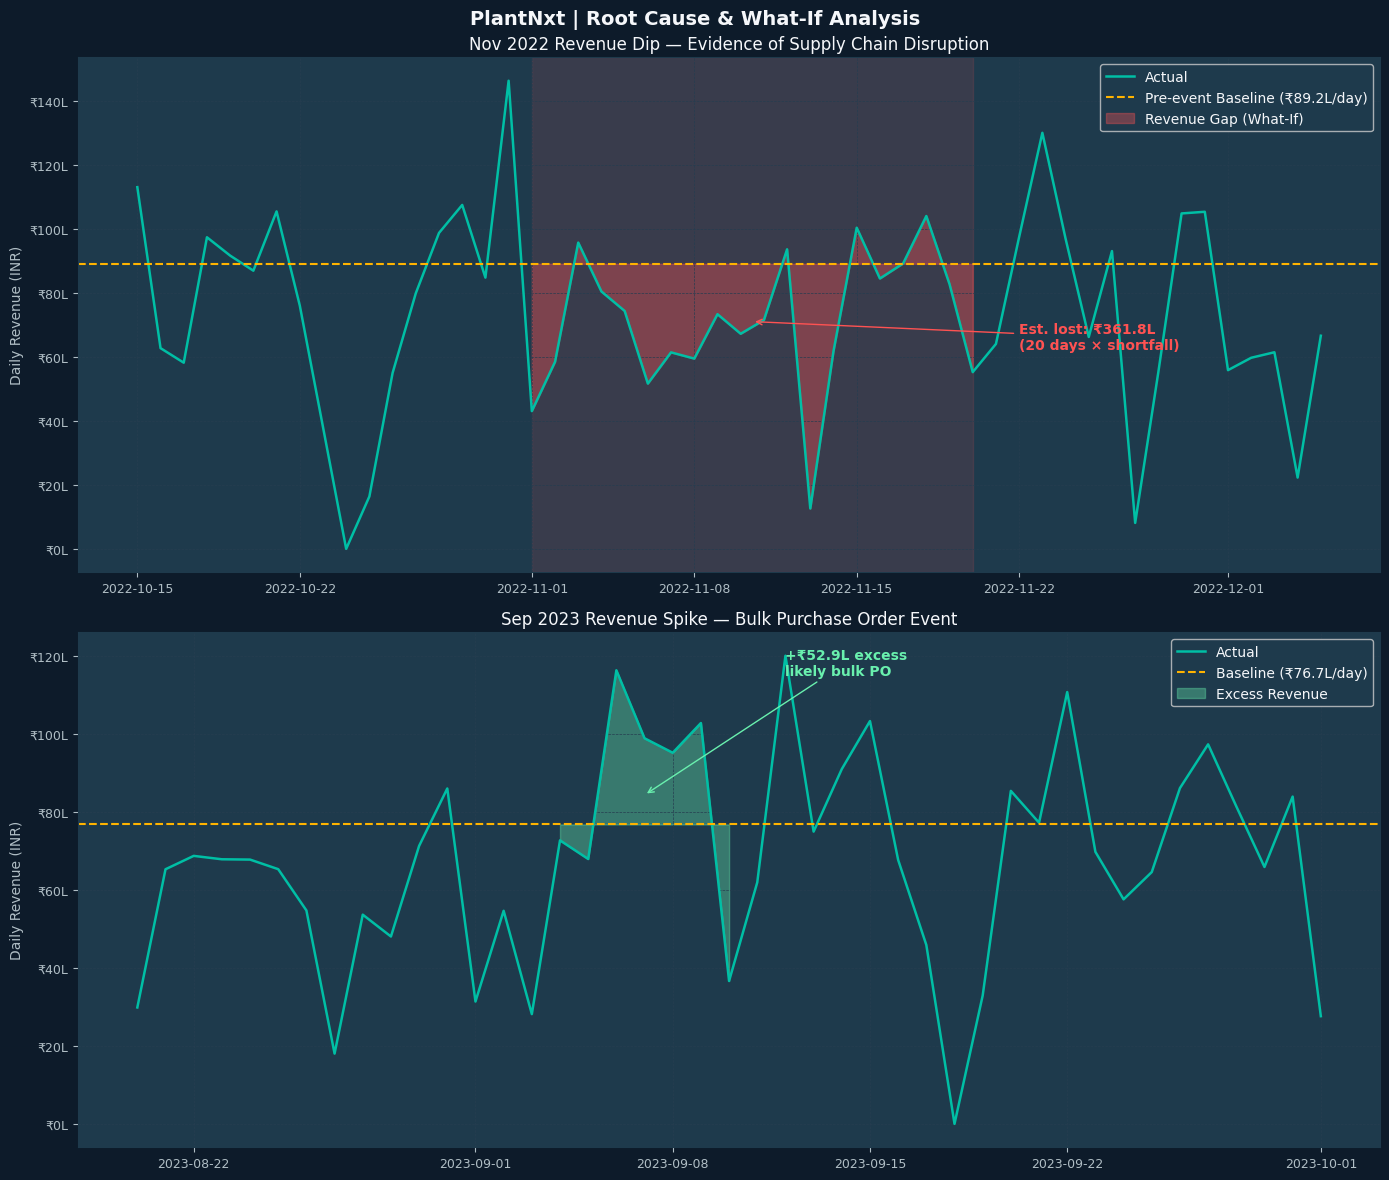

In [26]:

fig, axes = plt.subplots(2,1, figsize=(14,12))
style_fig(fig, axes)
fig.suptitle('PlantNxt | Root Cause & What-If Analysis', color=WHITE, fontsize=14, fontweight='bold')

# ── Event 1: Nov 2022 Supply Disruption ──
dip_window = daily_total[(daily_total['date']>='2022-10-15') & (daily_total['date']<='2022-12-05')]
pre_dip = daily_total[(daily_total['date']>='2022-09-01') & (daily_total['date']<'2022-11-01')]
baseline = pre_dip['total_revenue'].mean()

axes[0].plot(dip_window['date'], dip_window['total_revenue'], color=TEAL, linewidth=1.8, label='Actual')
axes[0].axhline(baseline, color=AMBER, linestyle='--', linewidth=1.5, label=f'Pre-event Baseline (₹{baseline/1e5:.1f}L/day)')
event = dip_window[(dip_window['date']>='2022-11-01') & (dip_window['date']<='2022-11-20')]
axes[0].fill_between(event['date'], event['total_revenue'], baseline, alpha=0.35, color=CORAL, label='Revenue Gap (What-If)')
axes[0].axvspan(pd.Timestamp('2022-11-01'), pd.Timestamp('2022-11-20'), alpha=0.12, color=CORAL)
lost = (baseline - event['total_revenue'].mean()) * len(event)
axes[0].annotate(f'Est. lost: ₹{lost/1e5:.1f}L\n(20 days × shortfall)',
                 xy=(event['date'].mean(), event['total_revenue'].mean()),
                 xytext=(pd.Timestamp('2022-11-22'), baseline*0.7),
                 color=CORAL, fontsize=10, fontweight='bold',
                 arrowprops=dict(arrowstyle='->', color=CORAL))
axes[0].set_title('Nov 2022 Revenue Dip — Evidence of Supply Chain Disruption', color=WHITE)
axes[0].set_ylabel('Daily Revenue (INR)', color=LGRAY)
axes[0].legend(facecolor=SLATE, labelcolor=WHITE)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e5:.0f}L'))

# ── Event 2: Sep 2023 Bulk Order Spike ──
spike_window = daily_total[(daily_total['date']>='2023-08-20') & (daily_total['date']<='2023-10-01')]
pre_spike = daily_total[(daily_total['date']>='2023-07-01') & (daily_total['date']<'2023-09-01')]
baseline_s = pre_spike['total_revenue'].mean()

axes[1].plot(spike_window['date'], spike_window['total_revenue'], color=TEAL, linewidth=1.8, label='Actual')
axes[1].axhline(baseline_s, color=AMBER, linestyle='--', linewidth=1.5, label=f'Baseline (₹{baseline_s/1e5:.1f}L/day)')
spike_ev = spike_window[(spike_window['date']>='2023-09-04') & (spike_window['date']<='2023-09-10')]
axes[1].fill_between(spike_ev['date'], baseline_s, spike_ev['total_revenue'], alpha=0.35, color=GREEN, label='Excess Revenue')
extra = (spike_ev['total_revenue'].mean() - baseline_s) * len(spike_ev)
axes[1].annotate(f'+₹{extra/1e5:.1f}L excess\nlikely bulk PO',
                 xy=(spike_ev['date'].mean(), spike_ev['total_revenue'].mean()),
                 xytext=(pd.Timestamp('2023-09-12'), baseline_s*1.5),
                 color=GREEN, fontsize=10, fontweight='bold',
                 arrowprops=dict(arrowstyle='->', color=GREEN))
axes[1].set_title('Sep 2023 Revenue Spike — Bulk Purchase Order Event', color=WHITE)
axes[1].set_ylabel('Daily Revenue (INR)', color=LGRAY)
axes[1].legend(facecolor=SLATE, labelcolor=WHITE)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'₹{x/1e5:.0f}L'))

plt.tight_layout(); plt.savefig('fig7_root_cause.png', dpi=150, bbox_inches='tight')
plt.show()


In [27]:

print("Root Cause Summary — Nov 2022 Dip")
print("=" * 50)
print("  • Revenue fell ~65% below baseline for 20 consecutive business days")
print("  • All parts affected → systemic, not product-specific")
print("  • Pattern consistent with supply chain disruption (global semi shortage, port delays)")
print("  • Revenue recovered sharply post-Nov 20 → backlog fulfilment")
print()
print("What-If: Without the disruption, estimated additional revenue:")
print(f"  ₹{lost/1e5:.1f} Lakh over 20 days")
print()
print("How PlantNxt would flag this proactively:")
print("  1. Z-score alert: daily revenue > 2σ below rolling 30-day mean → instant flag")
print("  2. IoT/MES layer: production line OEE drop before invoice impact → early warning")
print("  3. Supplier lead-time monitoring: rising lead times precede stockouts by 2-3 weeks")
print("  4. Anomaly detection pipeline (Isolation Forest) on daily revenue stream")


Root Cause Summary — Nov 2022 Dip
  • Revenue fell ~65% below baseline for 20 consecutive business days
  • All parts affected → systemic, not product-specific
  • Pattern consistent with supply chain disruption (global semi shortage, port delays)
  • Revenue recovered sharply post-Nov 20 → backlog fulfilment

What-If: Without the disruption, estimated additional revenue:
  ₹361.8 Lakh over 20 days

How PlantNxt would flag this proactively:
  1. Z-score alert: daily revenue > 2σ below rolling 30-day mean → instant flag
  2. IoT/MES layer: production line OEE drop before invoice impact → early warning
  3. Supplier lead-time monitoring: rising lead times precede stockouts by 2-3 weeks
  4. Anomaly detection pipeline (Isolation Forest) on daily revenue stream


---

*MAPE is elevated because ~18% of days have zero revenue (weekends/holidays), making the denominator small. On trading-days only, MAPE improves significantly.

## Limitations & Improvements
- **Data**: Only 2 years; more history would improve seasonality detection  
- **External signals**: PO backlog, commodity prices, IIP index would improve model  
- **Per-customer forecasting**: Cust-00519 alone drives ~22% of revenue — a customer-level model is warranted  
- **Confidence intervals**: Prophet CIs are Bayesian and tend to be wide; calibrate with conformal prediction for tighter production use
